<a href="https://colab.research.google.com/github/anishgore78/Network-Intrusion-Detection/blob/main/NetworkIntrusionDetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import io
import joblib
import time

from scipy.io import arff
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report


In [9]:

import pandas as pd
import zipfile
import io
import re

def load_arff_zip(path):
    with zipfile.ZipFile(path, 'r') as z:
        arff_file = [f for f in z.namelist() if f.endswith('.arff')][0]

        with z.open(arff_file) as f:
            content = f.read().decode('utf-8')

    lines = content.splitlines()

    columns = []
    data_start = None

    for i, line in enumerate(lines):
        line = line.strip()

        if line.lower().startswith('@attribute'):
            match = re.match(
                r"""@attribute\s+(?:'([^']+)'|"([^"]+)"|(\S+))""",
                line,
                re.IGNORECASE
            )
            if match:
                columns.append(next(x for x in match.groups() if x is not None))

        elif line.lower() == '@data':
            data_start = i + 1
            break

    data = '\n'.join(lines[data_start:])

    df = pd.read_csv(
        io.StringIO(data),
        header=None,
        skipinitialspace=True
    )

    df.columns = columns

    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].astype(str).str.strip().str.strip("'").str.strip('"')

    return df

train_df = load_arff_zip('/content/KDDTrain+.arff.zip')
test_df = load_arff_zip('/content/KDDTest+.arff.zip')

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

display(train_df.head())




Training shape: (125973, 42)
Testing shape: (22544, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0,tcp,http,SF,232,8153,0,0,0,0,...,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


In [10]:
print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

print("\nMissing values:")
print(train_df.isnull().sum().sum())

print("\nTarget distribution:")
print(train_df['class'].value_counts())

print("\nData types:")
print(train_df.dtypes.value_counts())

Training shape: (125973, 42)
Testing shape: (22544, 42)

Columns:
['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'class']

Missing values:
0

Target distribution:
class
normal     67343
anomaly    58630
Name: count, dtype: int64

Data types:
int64      23
float64    15
object      4
Name: count, dtype: int64


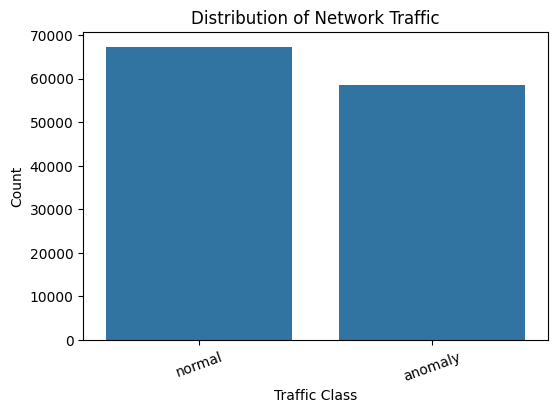

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x='class')
plt.title('Distribution of Network Traffic')
plt.xlabel('Traffic Class')
plt.ylabel('Count')
plt.xticks(rotation=20)
plt.show()

In [12]:
import numpy as np

X_train = train_df.drop(columns=['class']).copy()
X_test = test_df.drop(columns=['class']).copy()

y_train = (
    train_df['class'].astype(str).str.strip().str.lower() != 'normal'
).astype(int)

y_test = (
    test_df['class'].astype(str).str.strip().str.lower() != 'normal'
).astype(int)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training features: (125973, 41)
Testing features: (22544, 41)

Training target:
class
0    67343
1    58630
Name: count, dtype: int64

Testing target:
class
1    12833
0     9711
Name: count, dtype: int64


In [13]:
print("Same columns:", list(X_train.columns) == list(X_test.columns))

Same columns: True


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X_train.select_dtypes(exclude=['object']).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

print("Categorical columns:", categorical_cols)
print("Numerical columns:", len(numerical_cols))

Categorical columns: ['protocol_type', 'service', 'flag']
Numerical columns: 38


Training Four Models

In [15]:
import time
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        solver='liblinear'
    ),
    'KNN': KNeighborsClassifier(
        n_neighbors=5,
        weights='distance',
        n_jobs=-1
    ),
    'SVM': LinearSVC(
        class_weight='balanced',
        max_iter=5000
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

X_knn, _, y_knn, _ = train_test_split(
    X_train,
    y_train,
    train_size=min(30000, len(X_train)),
    stratify=y_train,
    random_state=42
)

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('model', model)
    ])

    start = time.time()

    if name == 'KNN':
        pipeline.fit(X_knn, y_knn)
    else:
        pipeline.fit(X_train, y_train)

    training_time = time.time() - start

    predictions = pipeline.predict(X_test)

    if hasattr(pipeline, 'predict_proba'):
        scores = pipeline.predict_proba(X_test)[:, 1]
    else:
        scores = pipeline.decision_function(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1 Score': f1_score(y_test, predictions, zero_division=0),
        'ROC AUC': roc_auc_score(y_test, scores),
        'Training Time (sec)': round(training_time, 2)
    })

    trained_models[name] = pipeline

    print(name, "completed")

Logistic Regression completed
KNN completed
SVM completed
Random Forest completed


In [16]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Training Time (sec)
0,KNN,0.7736,0.9675,0.6232,0.7581,0.8142,0.10
1,Random Forest,0.7685,0.9678,0.6137,0.7511,0.9595,34.62
2,Logistic Regression,0.7536,0.9168,0.6238,0.7424,0.7932,29.59
3,SVM,0.7532,0.9160,0.6236,0.7420,0.7861,6.38


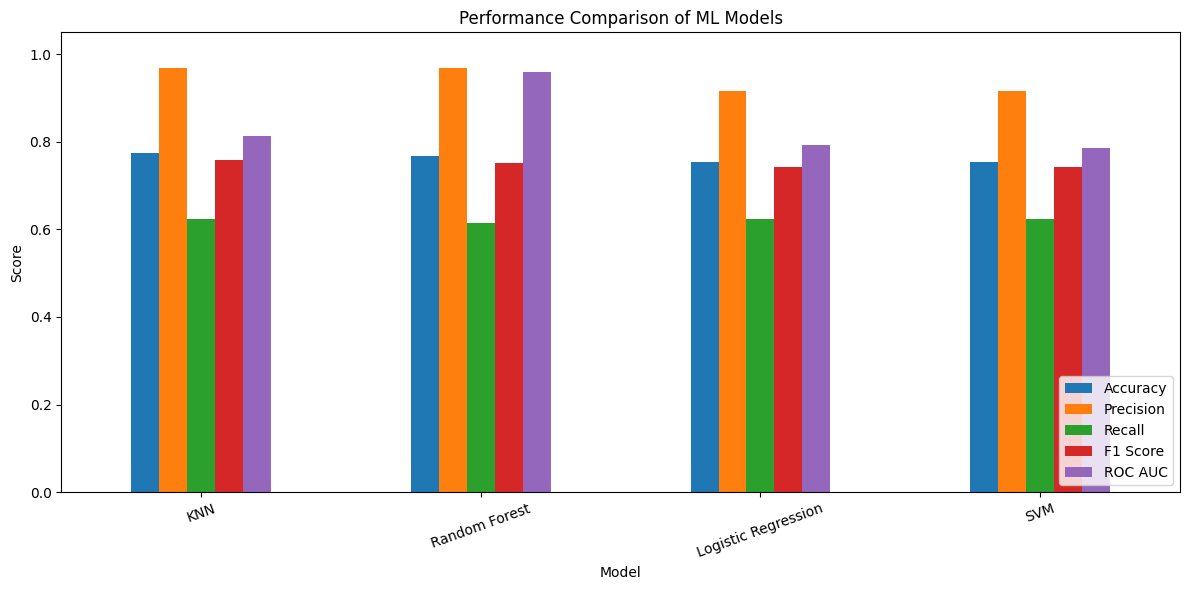

In [17]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC AUC']

results_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Performance Comparison of ML Models')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [18]:
results_df.to_csv('model_comparison.csv', index=False)

In [19]:
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:", results_df.iloc[0]['F1 Score'])

Best Model: KNN
Best F1 Score: 0.7581042654028436


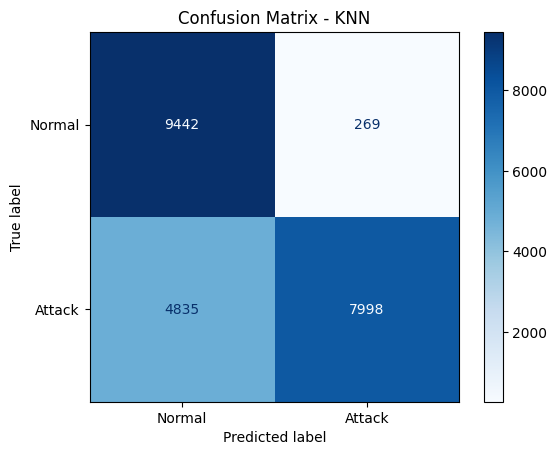

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Normal', 'Attack']
)

disp.plot(cmap='Blues')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.show()

In [21]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    best_predictions,
    target_names=['Normal', 'Attack']
))

              precision    recall  f1-score   support

      Normal       0.66      0.97      0.79      9711
      Attack       0.97      0.62      0.76     12833

    accuracy                           0.77     22544
   macro avg       0.81      0.80      0.77     22544
weighted avg       0.84      0.77      0.77     22544



In [26]:
rf_model = trained_models['Random Forest']

feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()

importances = rf_model.named_steps['model'].feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

display(feature_importance.head(15))

,Feature,Importance
1,num__src_bytes,0.140639
2,num__dst_bytes,0.093047
120,cat__flag_SF,0.085081
29,num__dst_host_srv_count,0.059333
8,num__logged_in,0.053635
25,num__same_srv_rate,0.049954
30,num__dst_host_same_srv_rate,0.046693
26,num__diff_srv_rate,0.042730
35,num__dst_host_srv_serror_rate,0.039929
19,num__count,0.030573


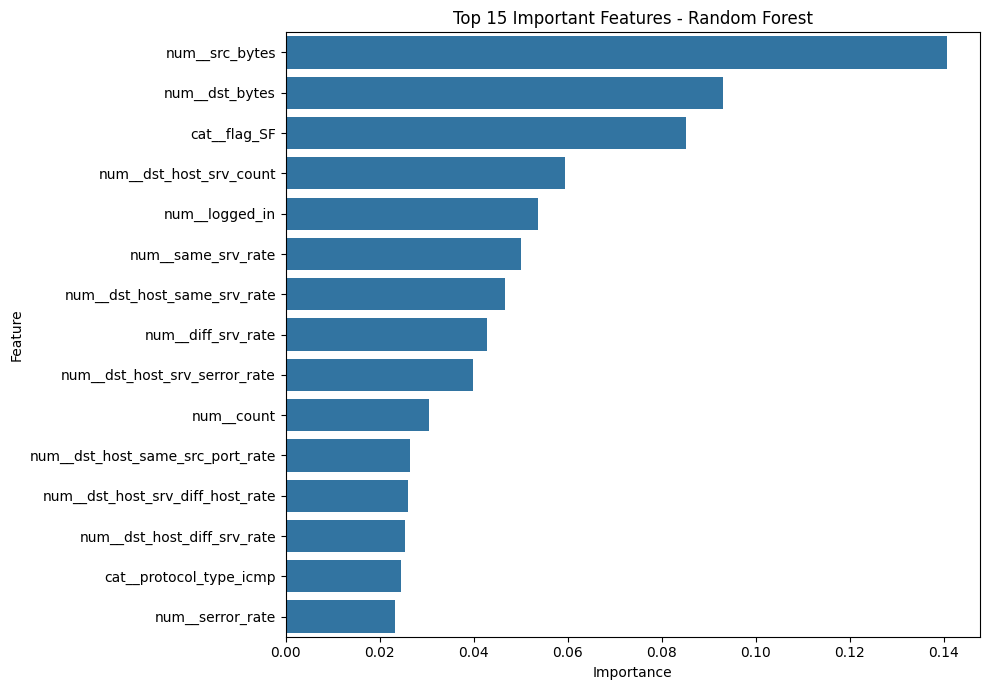

In [27]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Important Features - Random Forest')
plt.tight_layout()
plt.show()

In [28]:
sample = X_test.iloc[[0]]

prediction = best_model.predict(sample)[0]

if prediction == 1:
    print("Prediction: ATTACK DETECTED")
else:
    print("Prediction: NORMAL TRAFFIC")

print("Actual class:", "Attack" if y_test.iloc[0] == 1 else "Normal")

Prediction: ATTACK DETECTED
Actual class: Attack


In [29]:
sample_data = X_test.iloc[:10]

sample_predictions = best_model.predict(sample_data)

prediction_results = pd.DataFrame({
    'Actual': y_test.iloc[:10].map({0: 'Normal', 1: 'Attack'}).values,
    'Predicted': pd.Series(sample_predictions).map({0: 'Normal', 1: 'Attack'}).values
})

display(prediction_results)

,Actual,Predicted
0,Attack,Attack
1,Attack,Attack
2,Normal,Normal
3,Attack,Attack
4,Attack,Normal
5,Normal,Normal
6,Normal,Normal
7,Attack,Normal
8,Normal,Normal
9,Attack,Normal


In [30]:
import joblib

joblib.dump(best_model, 'nsl_kdd_best_model.pkl')

joblib.dump(
    trained_models['Random Forest'],
    'nsl_kdd_random_forest.pkl'
)

print("Models saved successfully!")

Models saved successfully!


In [31]:
import os
import shutil

os.makedirs('Network_Intrusion_Detection', exist_ok=True)

files = [
    'nsl_kdd_best_model.pkl',
    'nsl_kdd_random_forest.pkl',
    'model_comparison.csv'
]

for file in files:
    shutil.copy(file, 'Network_Intrusion_Detection/')

shutil.make_archive(
    'Network_Intrusion_Detection',
    'zip',
    'Network_Intrusion_Detection'
)

from google.colab import files
files.download('Network_Intrusion_Detection.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>